# Diabetes

Objectif :


Objectif : prédire si un patient est **diabétique (1)** ou non **(0)** à partir de 21 features (tension, cholestérol, IMC, activité physique, âge, revenu…).

Ce notebook couvre :
1. l'import des données,
2. le nettoyage et le prétraitement (valeurs manquantes, doublons, centrage-réduction, ACP),
3. la séparation train / test.
4. l'entraînement du jeu de données
5. la comparaison et la conclusion


La sélection de features et l'entraînement des modèles viendront ensuite. Toutes les fonctions utilisées sont dans `ml_workflow.py`.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

import ml_workflow as mw

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Listes de colonnes propres à Diabetes
# - features binaires (0 = non, 1 = oui)
DIABETE_BINARY = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack",
          "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare",
          "NoDocbcCost", "DiffWalk", "Sex"]

# - features ordinales (catégories dont l'ordre a un sens) : 
# santé générale (1 = excellente -> 5 = mauvaise), tranche d'âge (1 -> 13), niveau d'études (1 -> 6), revenu (1 -> 8) ;
DIABETE_ORDINAL = ["GenHlth", "Age", "Education", "Income"]

# - features numériques : IMC et nombre de jours de mauvaise santé mentale / physique sur les 30 derniers jours
DIABETE_NUMERIC = ["BMI", "MentHlth", "PhysHlth"]

## 1. Import des données

Le fichier `diabetes_binary_health_indicators_BRFSS2015.csv` a un en-tête.
La première colonne, `Diabetes_binary`, est la cible.

In [39]:
X, y = mw.load_diabetes()
print(X.shape, y.shape)
X.head()

(253680, 21) (253680,)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [40]:
mw.describe_dataset(X, y)

{'n_samples': 253680,
 'n_features': 21,
 'n_missing': 0,
 'n_duplicates': 24206,
 'class_ratio': {0: 0.861, 1: 0.139}}

### Répartition des classes

Environ 14 % de positifs : le dataset est **déséquilibré**, donc l'accuracy est trompeuse. On comparera les modèles sur le **rappel** et la **précision**. On stratifiera le split pour conserver cette proportion et lorsque le modèle le permet on pondérera les classes.

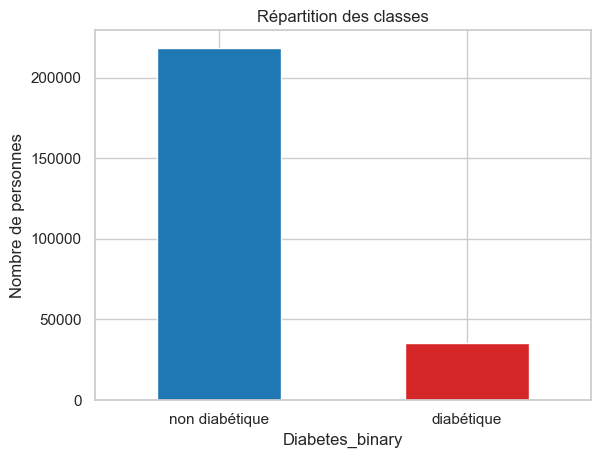

In [41]:
ax = y.value_counts().rename({0: "non diabétique", 1: "diabétique"}).plot.bar(color=["tab:blue", "tab:red"])
ax.set_title("Répartition des classes")
ax.set_ylabel("Nombre de personnes")
plt.xticks(rotation=0)
plt.show()

### Types de features

Les features sont de trois types :
- **14 binaires** (0 ou 1) : hypertension, cholestérol, tabac, AVC, activité physique…
- **4 ordinales** : état de santé général (1 = excellent → 5 = mauvais), tranche d'âge (1 → 13), niveau d'études (1 → 6), revenu (1 → 8). Leur ordre a un sens, on les garde donc telles quelles.
- **3 numériques** : l'IMC et le nombre de jours de mauvaise santé mentale / physique sur les 30 derniers jours.

In [42]:
pd.DataFrame({"type": ["binaire"] * len(DIABETE_BINARY) + ["ordinale"] * len(DIABETE_ORDINAL) + ["numérique"] * len(DIABETE_NUMERIC),
              "nb valeurs distinctes": X[DIABETE_BINARY + DIABETE_ORDINAL + DIABETE_NUMERIC].nunique().values},
              index=DIABETE_BINARY + DIABETE_ORDINAL + DIABETE_NUMERIC).T

,HighBP,HighChol,CholCheck,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,DiffWalk,Sex,GenHlth,Age,Education,Income,BMI,MentHlth,PhysHlth
type,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,ordinale,ordinale,ordinale,ordinale,numérique,numérique,numérique
nb valeurs distinctes,2,2,2,2,2,2,2,2,2,2,2,2,2,2,5,13,6,8,84,31,31


In [43]:
X[DIABETE_ORDINAL + DIABETE_NUMERIC].describe().T

,count,mean,std,min,25%,50%,75%,max
GenHlth,253680.0,2.511392,1.068477,1.0,2.0,2.0,3.0,5.0
Age,253680.0,8.032119,3.054220,1.0,6.0,8.0,10.0,13.0
Education,253680.0,5.050434,0.985774,1.0,4.0,5.0,6.0,6.0
Income,253680.0,6.053875,2.071148,1.0,5.0,7.0,8.0,8.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
MentHlth,253680.0,3.184772,7.412847,0.0,0.0,0.0,2.0,30.0
PhysHlth,253680.0,4.242081,8.717951,0.0,0.0,0.0,3.0,30.0


### Features numériques

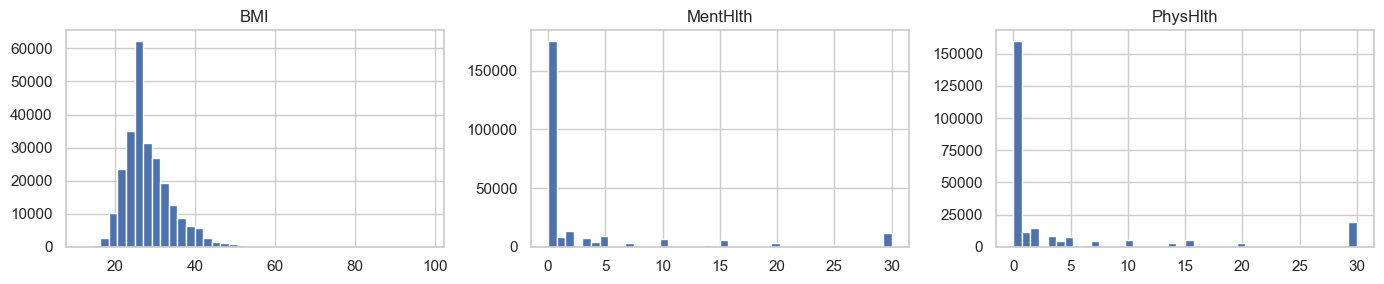

BMI standardisé : max z = 10.5
Part de 0 : MentHlth 69%, PhysHlth 63%


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, col in zip(axes, DIABETE_NUMERIC):
    ax.hist(X[col], bins=40)
    ax.set_title(col)
plt.tight_layout()
plt.show()

z_bmi = (X["BMI"] - X["BMI"].mean()) / X["BMI"].std()
print(f"BMI standardisé : max z = {z_bmi.max():.1f}")
print(f"Part de 0 : MentHlth {(X['MentHlth'] == 0).mean():.0%}, PhysHlth {(X['PhysHlth'] == 0).mean():.0%}")

`MentHlth` et `PhysHlth` valent 0 pour la majorité des personnes (69 % et 63 %). L'IMC est légèrement asymétrique, avec quelques valeurs très élevées (jusqu'à 98, soit z ≈ 10 après standardisation), mais elles sont rares et restent plausibles. 
On ne fait donc pas de transformation $\log(1+x)$ : la standardisation suffit.

### Corrélation avec la cible

Première idée des features utiles (corrélation linéaire seulement, la sélection de features sera faite proprement plus tard).

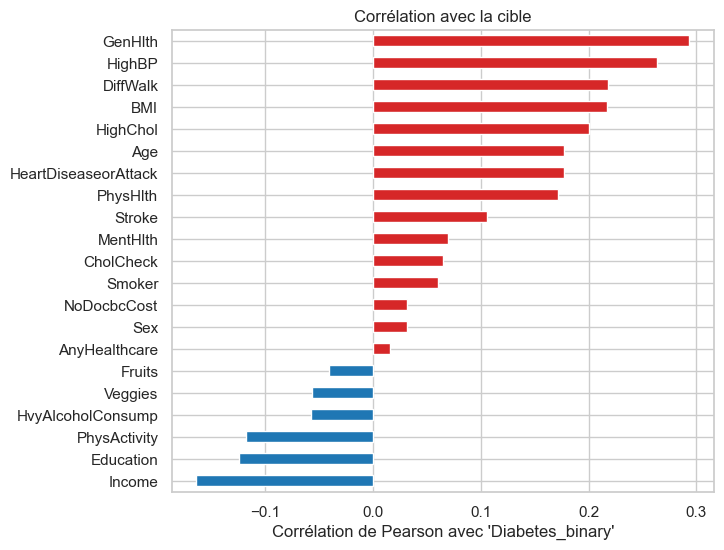

In [45]:
corr = X.corrwith(y).sort_values()
corr.plot.barh(figsize=(7, 6), color=["tab:red" if v > 0 else "tab:blue" for v in corr])
plt.title("Corrélation avec la cible")
plt.xlabel("Corrélation de Pearson avec 'Diabetes_binary'")
plt.show()

- Les plus liées positivement au diabète sont l'état de santé général (`GenHlth`), l'hypertension (`HighBP`), les difficultés à marcher (`DiffWalk`), l'IMC (`BMI`) et le cholestérol.

- Le revenu (`Income`), le niveau d'études (`Education`) et l'activité physique (`PhysActivity`) sont liés négativement.

## 2. Nettoyage

### Valeurs manquantes

La documentation annonce aucune valeur manquante, on le vérifie. La fonction `mw.preprocess` contient tout de même une étape d'imputation (moyenne du train), pour que le workflow reste générique.

In [46]:
print("Valeurs manquantes :", X.isna().sum().sum())

Valeurs manquantes : 0


### Doublons

Environ 24 000 lignes sont des doublons exacts (mêmes réponses et même label). On les supprime **avant le split** : sinon une même ligne pourrait se retrouver à la fois dans le train et dans le test, ce qui surestimerait les performances.

In [47]:
n_before = len(X)
X_clean, y_clean = mw.remove_duplicates(X, y)
print(f"{n_before - len(X_clean)} doublons supprimés -> {len(X_clean)} personnes")
print("Part de positifs après nettoyage :", round(y_clean.mean(), 3))

24206 doublons supprimés -> 229474 personnes
Part de positifs après nettoyage : 0.153


In [48]:
X_clean[DIABETE_NUMERIC].describe().T

,count,mean,std,min,25%,50%,75%,max
BMI,229474.0,28.687507,6.789204,12.0,24.0,27.0,32.0,98.0
MentHlth,229474.0,3.509866,7.717643,0.0,0.0,0.0,2.0,30.0
PhysHlth,229474.0,4.681219,9.050877,0.0,0.0,0.0,4.0,30.0


## 3. Séparation train / test

Split **stratifié** 80 / 20 : le test set ne sera utilisé qu'à la toute fin, pour évaluer le modèle retenu. Le choix des hyperparamètres et des features se fera par validation croisée sur le train.

In [49]:
X_train, X_test, y_train, y_test = mw.split_data(X_clean, y_clean, test_size=0.2,
                                                 random_state=RANDOM_STATE)
print("Train :", X_train.shape, "| part de positifs :", round(y_train.mean(), 3))
print("Test  :", X_test.shape, "| part de positifs :", round(y_test.mean(), 3))

Train : (183579, 21) | part de positifs : 0.153
Test  : (45895, 21) | part de positifs : 0.153


### Centrage-réduction

Ajusté sur le train uniquement, puis appliqué au test :

$$
z_{ij} = \frac{x_{ij} - \mu_j^{\text{train}}}{\sigma_j^{\text{train}}}
$$

Sur le train, chaque feature a donc une moyenne de 0 et un écart-type de 1 ; sur le test, c'est seulement approximatif, ce qui est normal.

In [50]:
X_train_s, X_test_s, tr = mw.preprocess(X_train, X_test, impute_strategy="mean", scale=True)
pd.DataFrame({
    "moyenne train": X_train_s.mean().round(3),
    "écart-type train": X_train_s.std(ddof=0).round(3),
    "moyenne test": X_test_s.mean().round(3),
    "écart-type test": X_test_s.std(ddof=0).round(3),
}).head(8)

,moyenne train,écart-type train,moyenne test,écart-type test
HighBP,0.0,1.0,0.002,1.000
HighChol,0.0,1.0,0.001,1.000
CholCheck,0.0,1.0,-0.003,1.007
BMI,-0.0,1.0,0.008,1.016
Smoker,-0.0,1.0,0.005,1.000
Stroke,-0.0,1.0,0.008,1.018
HeartDiseaseorAttack,0.0,1.0,0.006,1.008
PhysActivity,-0.0,1.0,-0.011,1.006


### ACP

On étudie la variance expliquée par les composantes principales (ACP ajustée sur le train standardisé). Si peu de composantes suffisaient, l'ACP serait une bonne réduction de dimension.

80% de variance expliquée -> 14 composantes sur 21
90% de variance expliquée -> 17 composantes sur 21
95% de variance expliquée -> 19 composantes sur 21


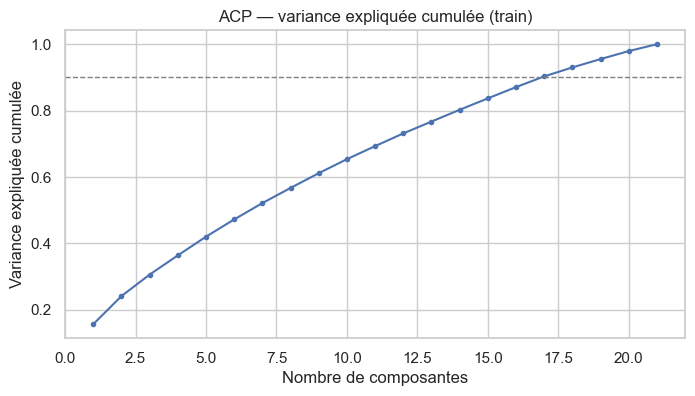

In [51]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

for seuil in (0.8, 0.9, 0.95):
    k = int(np.searchsorted(cum_var, seuil) + 1)
    print(f"{seuil:.0%} de variance expliquée -> {k} composantes sur {X_train_s.shape[1]}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker=".")
plt.axhline(0.9, color="grey", ls="--", lw=1)
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("ACP — variance expliquée cumulée (train)")
plt.show()

Il faut 17 composantes sur 21 pour garder 90 % de la variance : les features sont peu corrélées entre elles et l'ACP compresse peu.

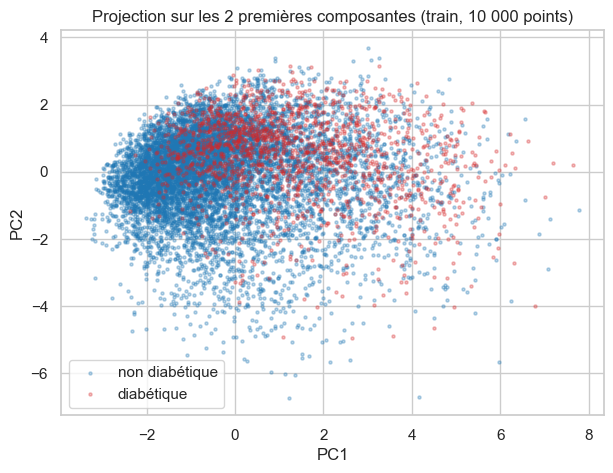

In [52]:
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_s)
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(pcs), 10000, replace=False)  # 10 000 points pour garder un graphe lisible
plt.figure(figsize=(7, 5))
for label, name, c in [(0, "non diabétique", "tab:blue"), (1, "diabétique", "tab:red")]:
    m = (y_train.to_numpy()[idx] == label)
    plt.scatter(pcs[idx][m, 0], pcs[idx][m, 1], s=5, alpha=0.3, c=c, label=name)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Projection sur les 2 premières composantes (train, 10 000 points)")
plt.legend()
plt.show()

Les diabétiques sont plutôt situés vers les PC1 élevées, mais les deux classes se chevauchent fortement : le problème est intrinsèquement difficile (21 réponses à un questionnaire ne suffisent pas à poser un diagnostic). On testera quand même la variante ACP 90 %.

## Jeux de données prêts pour la suite

`mw.prepare_data` refait les étapes 1 à 3 en une ligne. On prépare les variantes à comparer lors de l'entraînement :
- **full** : les 21 features, standardisées ;
- **acp90** : composantes principales expliquant 90 % de la variance.

In [53]:
datasets = {
    "full": mw.prepare_data("diabetes", random_state=RANDOM_STATE),
    "acp90": mw.prepare_data("diabetes", pca_components=0.9, random_state=RANDOM_STATE),
}

for name, (Xtr, Xte, ytr, yte, _) in datasets.items():
    print(f"{name:6s} train {Xtr.shape}  test {Xte.shape}")

full   train (183579, 21)  test (45895, 21)
acp90  train (183579, 17)  test (45895, 17)


**Bilan des étapes 1 à 3**

- 253 680 personnes, 21 features (14 binaires, 4 ordinales, 3 numériques), **aucune valeur manquante**, 24 206 doublons supprimés.
- Classes **déséquilibrées** (~15 % de positifs après nettoyage) → split stratifié, pondération des classes, métriques rappel / précision.
- Échelles différentes (IMC, âge vs binaires) → centrage-réduction.
- L'ACP compresse peu et les classes se chevauchent : on s'attend à des performances modestes, quel que soit le modèle.

## 4. Entraînement

### Taille des données

Le train fait environ 184 000 lignes. Faire toutes les validations croisées dessus serait très long (surtout pour le k-NN, qui compare chaque point à tout le train, et pour le Random Forest). 

On fait donc les **réglages et la comparaison par validation croisée sur un sous-échantillon stratifié de 30 000 lignes du train**, puis on **réentraîne les modèles retenus sur tout le train** avant l'évaluation finale sur le test.

In [54]:
Xtr, Xte, ytr, yte, _ = datasets["full"]

# Sous-échantillon stratifié du train pour les validations croisées
_, X_cv, _, y_cv = mw.split_data(Xtr, ytr, test_size=30000, random_state=RANDOM_STATE)
print("Sous-échantillon :", X_cv.shape, "| part de positifs :", round(y_cv.mean(), 3))

Sous-échantillon : (30000, 21) | part de positifs : 0.153


### k-NN : choix de k

Le k-NN n'accepte pas de pondération des classes : avec 85 % de négatifs, la majorité des voisins sont presque toujours négatifs. On choisit k par validation croisée (accuracy, critère utilisé par `mw.choose_k_knn`).

k = 71


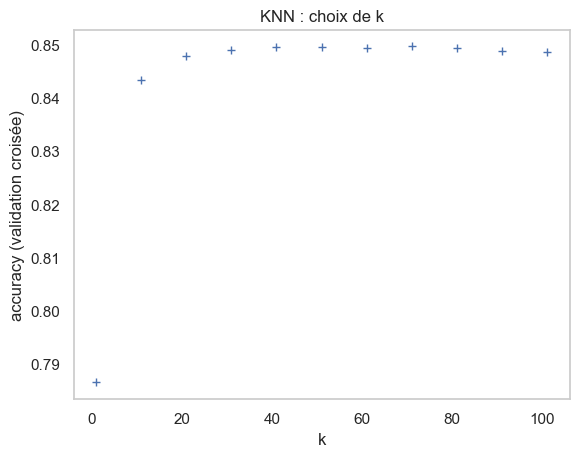

In [55]:
best_k, ks, scores = mw.choose_k_knn(X_cv, y_cv, list(range(1, 102, 10)))
print("k =", best_k)

plt.plot(ks, scores, "+")
plt.xlabel("k")
plt.ylabel("accuracy (validation croisée)")
plt.title("KNN : choix de k")
plt.grid()
plt.show()

### Réseau de neurones : choix du learning rate

On redécoupe le sous-échantillon en train + validation (le test n'est pas touché).

lr=0.01 : loss train 0.357, validation 0.360
lr=0.1 : loss train 0.335, validation 0.345
lr=0.5 : loss train 0.325, validation 0.348


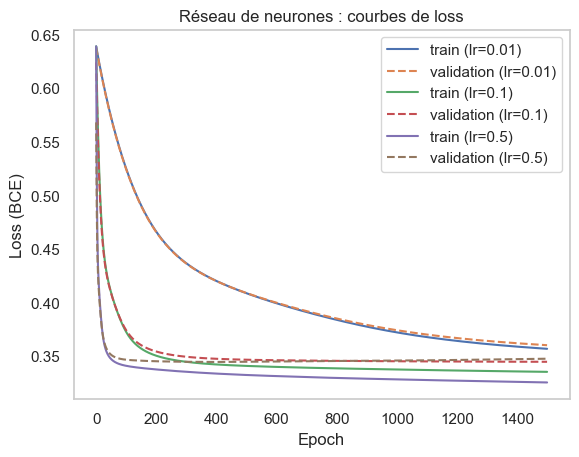

In [56]:
X_fit, X_val, y_fit, y_val = mw.split_data(X_cv, y_cv, 0.2, RANDOM_STATE)

for lr in [0.01, 0.1, 0.5]:
    model, losses, val_losses = mw.train_mlp(X_fit, y_fit, 32, 16, 1500, lr, X_val, y_val)
    plt.plot(losses, label=f"train (lr={lr})")
    plt.plot(val_losses, "--", label=f"validation (lr={lr})")
    print(f"lr={lr} : loss train {losses[-1]:.3f}, validation {val_losses[-1]:.3f}")

plt.xlabel("Epoch")
plt.ylabel("Loss (BCE)")
plt.title("Réseau de neurones : courbes de loss")
plt.legend()
plt.grid()
plt.show()

### Sélection de features

Pour chaque modèle, on cherche le nombre de features à garder . 

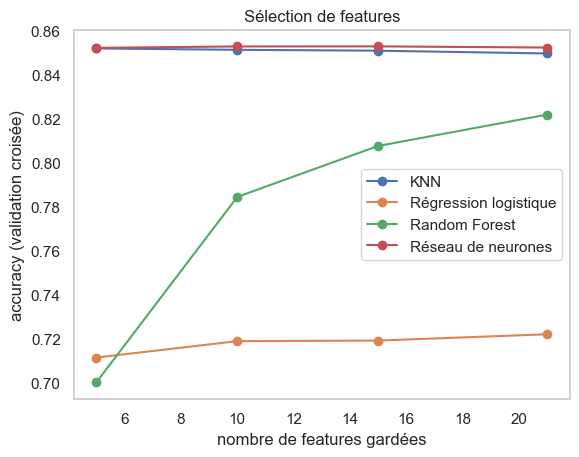

{'KNN': 5,
 'Régression logistique': 21,
 'Random Forest': 21,
 'Réseau de neurones': 15}

In [ ]:
models = mw.get_models(best_k, "balanced")  # "balanced" : dataset déséquilibré

n_values = [5, 10, 15, Xtr.shape[1]]
best_n = {}
for name, model in models.items():
    n, ns, sc = mw.choose_n_features(model, X_cv, y_cv, n_values)
    best_n[name] = n
    plt.plot(ns, sc, "o-", label=name)

plt.xlabel("nombre de features gardées")
plt.ylabel("accuracy (validation croisée)")
plt.title("Sélection de features")
plt.legend()
plt.grid()
plt.show()
best_n